In [89]:
print("Customer Churn Prediction")
print("Supervised, Semi-Supervised and Ensemble Learning")


Customer Churn Prediction
Supervised, Semi-Supervised and Ensemble Learning


In [90]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [91]:
# Load the Customer Churn dataset

df = pd.read_csv("Telco-Customer-churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (100000, 9)


,CustomerID,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,1,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,2,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,3,46,Female,10,52.47,One year,Electronic check,537.88,No
3,4,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,5,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No


In [92]:
# Basic information about the dataset

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape:
(100000, 9)

Column Names:
['CustomerID', 'Age', 'Gender', 'Tenure', 'MonthlyCharges', 'Contract', 'PaymentMethod', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   CustomerID      100000 non-null  int64  
 1   Age             100000 non-null  int64  
 2   Gender          100000 non-null  object 
 3   Tenure          100000 non-null  int64  
 4   MonthlyCharges  100000 non-null  float64
 5   Contract        100000 non-null  object 
 6   PaymentMethod   100000 non-null  object 
 7   TotalCharges    100000 non-null  float64
 8   Churn           100000 non-null  object 
dtypes: float64(2), int64(3), object(4)
memory usage: 6.9+ MB


In [93]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
CustomerID        0
Age               0
Gender            0
Tenure            0
MonthlyCharges    0
Contract          0
PaymentMethod     0
TotalCharges      0
Churn             0
dtype: int64


In [94]:
# Check the target variable

print("Customer Churn Distribution:")
print(df["Churn"].value_counts())

print("\nPercentage Distribution:")
print(df["Churn"].value_counts(normalize=True) * 100)

Customer Churn Distribution:
Churn
No     66856
Yes    33144
Name: count, dtype: int64

Percentage Distribution:
Churn
No     66.856
Yes    33.144
Name: proportion, dtype: float64


In [95]:
# Convert TotalCharges from text to numeric

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges after conversion:")
print(df["TotalCharges"].isnull().sum())

Missing TotalCharges after conversion:
0


In [96]:
# Remove rows with missing values

df = df.dropna()

print("Dataset shape after cleaning:")
print(df.shape)

Dataset shape after cleaning:
(100000, 9)


In [97]:
# Remove customer ID

df = df.drop("CustomerID", axis=1)

print("Customer ID removed.")
print(df.head())

Customer ID removed.
   Age  Gender  Tenure  MonthlyCharges        Contract     PaymentMethod  \
0   56  Female      68          147.58        Two year     Bank transfer   
1   69    Male      32           22.54  Month-to-month      Mailed check   
2   46  Female      10           52.47        One year  Electronic check   
3   32    Male      22          109.67  Month-to-month      Mailed check   
4   60  Female      54          130.98  Month-to-month       Credit card   

   TotalCharges Churn  
0      10052.03    No  
1        686.78    No  
2        537.88    No  
3       2390.04   Yes  
4       7081.28    No  


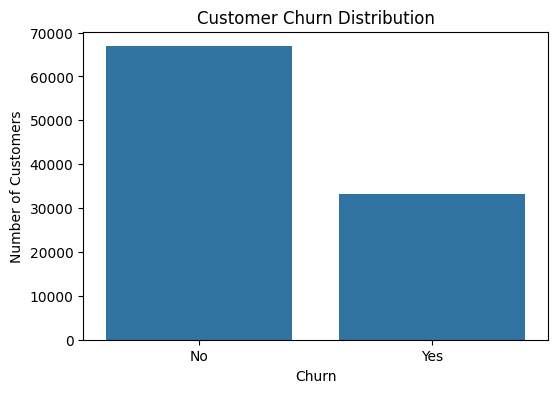

In [98]:
# Customer Churn Distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

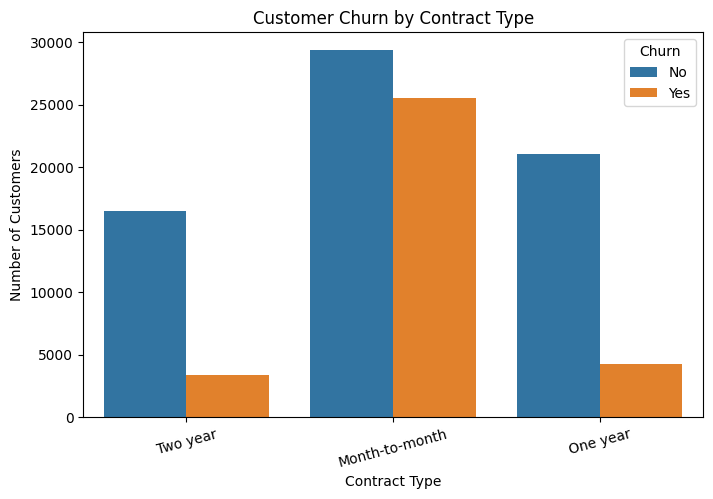

In [99]:
# Churn by Contract Type

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.show()

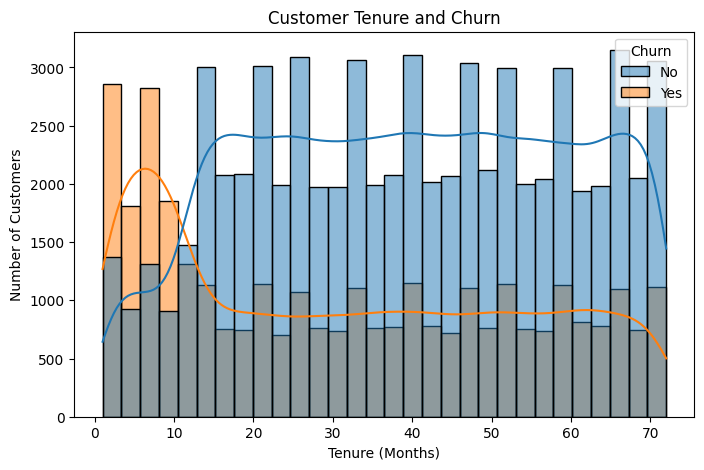

In [100]:
# Tenure distribution by churn

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Tenure",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Customer Tenure and Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

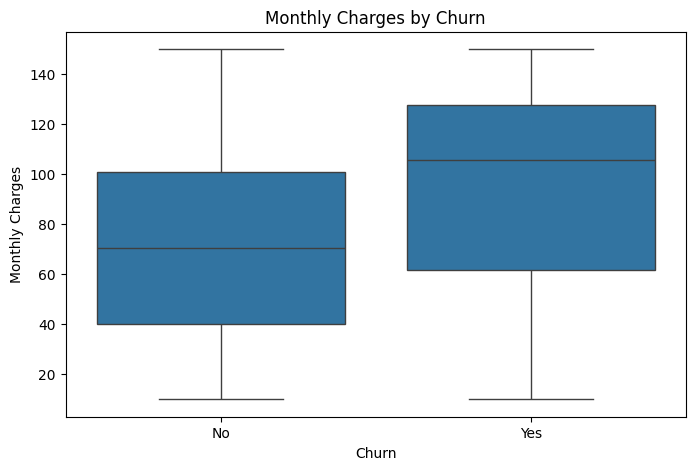

In [101]:
# Monthly Charges and Churn

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

Exploratory Data Analysis

Exploratory data analysis was performed to understand customer churn patterns. The churn distribution shows the proportion of customers who stayed and those who left. Contract type, customer tenure and monthly charges were also analyzed to identify their relationship with customer churn. These observations help in understanding the dataset before applying machine-learning algorithms.

In [102]:
# Separate features and target

X = df.drop("Churn", axis=1)
y = df["Churn"].map({"Yes": 1, "No": 0})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (100000, 7)
Target shape: (100000,)


In [103]:
# Convert categorical features into numerical features

X = pd.get_dummies(X, drop_first=True)  # One-Hot Encoding

print("Features after encoding:", X.shape)
print(X.head())

Features after encoding: (100000, 11)
   Age  Tenure  MonthlyCharges  TotalCharges  Gender_Male  Gender_Other  \
0   56      68          147.58      10052.03        False         False   
1   69      32           22.54        686.78         True         False   
2   46      10           52.47        537.88        False         False   
3   32      22          109.67       2390.04         True         False   
4   60      54          130.98       7081.28        False         False   

   Contract_One year  Contract_Two year  PaymentMethod_Credit card  \
0              False               True                      False   
1              False              False                      False   
2               True              False                      False   
3              False              False                      False   
4              False              False                       True   

   PaymentMethod_Electronic check  PaymentMethod_Mailed check  
0                         

In [104]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 80000
Testing samples: 20000


In [105]:
# Scale the features

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed!
Training data shape: (80000, 11)
Testing data shape: (20000, 11)


In [106]:
# Supervised Learning - Decision Tree

from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print("Decision Tree Results")
print(classification_report(y_test, y_pred_tree))

Decision Tree Results
              precision    recall  f1-score   support

           0       0.80      0.86      0.83     13371
           1       0.67      0.56      0.61      6629

    accuracy                           0.76     20000
   macro avg       0.73      0.71      0.72     20000
weighted avg       0.76      0.76      0.76     20000



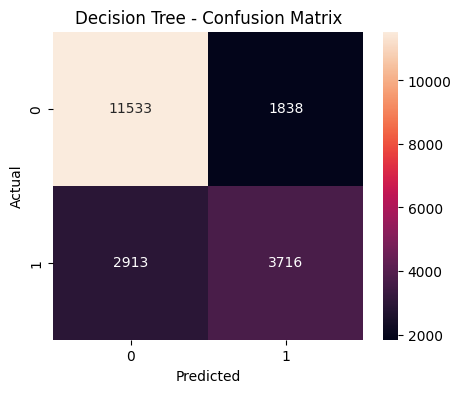

In [107]:
# Confusion Matrix - Decision Tree

cm = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [108]:
print("Decision Tree Performance")

print("Accuracy :", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall   :", recall_score(y_test, y_pred_tree))
print("F1 Score :", f1_score(y_test, y_pred_tree))

Decision Tree Performance
Accuracy : 0.76245
Precision: 0.6690673388548793
Recall   : 0.5605672047065923
F1 Score : 0.6100303701879668


In [109]:
# Semi-Supervised Learning - Label Spreading

from sklearn.semi_supervised import LabelSpreading

# Make a copy of the training labels
y_semi = y_train.to_numpy().copy()

# Random generator for reproducibility
rng = np.random.RandomState(42)

# Hide 70% of the training labels
unlabeled_indices = rng.choice(
    len(y_semi),
    size=int(0.70 * len(y_semi)),
    replace=False
)

# -1 means "unlabeled" for Label Spreading
y_semi[unlabeled_indices] = -1

print("Total training samples:", len(y_semi))
print("Labeled samples:", np.sum(y_semi != -1))
print("Unlabeled samples:", np.sum(y_semi == -1))

Total training samples: 80000
Labeled samples: 24000
Unlabeled samples: 56000


In [110]:
# Train the Semi-Supervised Label Spreading model

label_spread = LabelSpreading(
    kernel="knn",
    n_neighbors=7,
    max_iter=30
)

label_spread.fit(X_train_scaled, y_semi)

y_pred_semi = label_spread.predict(X_test_scaled)

print("Semi-Supervised Learning Results")
print(classification_report(y_test, y_pred_semi))

Semi-Supervised Learning Results
              precision    recall  f1-score   support

           0       0.77      0.81      0.79     13371
           1       0.56      0.50      0.53      6629

    accuracy                           0.71     20000
   macro avg       0.66      0.65      0.66     20000
weighted avg       0.70      0.71      0.70     20000



In [111]:
print("Label Spreading Performance")
print("---------------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_semi))
print("Precision:", precision_score(y_test, y_pred_semi))
print("Recall   :", recall_score(y_test, y_pred_semi))
print("F1 Score :", f1_score(y_test, y_pred_semi))

Label Spreading Performance
---------------------------
Accuracy : 0.7051
Precision: 0.5618757406466903
Recall   : 0.5006788354201237
F1 Score : 0.5295149968091896


In [112]:
# Ensemble Learning - Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Results")
print(classification_report(y_test, y_pred_rf))

Random Forest Results
              precision    recall  f1-score   support

           0       0.78      0.84      0.81     13371
           1       0.62      0.51      0.56      6629

    accuracy                           0.73     20000
   macro avg       0.70      0.68      0.68     20000
weighted avg       0.72      0.73      0.72     20000



In [113]:
print("Random Forest Performance")
print("-------------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))

Random Forest Performance
-------------------------
Accuracy : 0.732
Precision: 0.616400660429279
Recall   : 0.5068637803590285
F1 Score : 0.5562913907284768


In [114]:
# Final Model Comparison

print("========== FINAL MODEL COMPARISON ==========\n")

print("Decision Tree")
print("Accuracy :", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall   :", recall_score(y_test, y_pred_tree))
print("F1 Score :", f1_score(y_test, y_pred_tree))

print("\nLabel Spreading")
print("Accuracy :", accuracy_score(y_test, y_pred_semi))
print("Precision:", precision_score(y_test, y_pred_semi))
print("Recall   :", recall_score(y_test, y_pred_semi))
print("F1 Score :", f1_score(y_test, y_pred_semi))

print("\nRandom Forest")
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))

print("\nComparison completed!")

========== FINAL MODEL COMPARISON ==========

Decision Tree
Accuracy : 0.76245
Precision: 0.6690673388548793
Recall   : 0.5605672047065923
F1 Score : 0.6100303701879668

Label Spreading
Accuracy : 0.7051
Precision: 0.5618757406466903
Recall   : 0.5006788354201237
F1 Score : 0.5295149968091896

Random Forest
Accuracy : 0.732
Precision: 0.616400660429279
Recall   : 0.5068637803590285
F1 Score : 0.5562913907284768

Comparison completed!


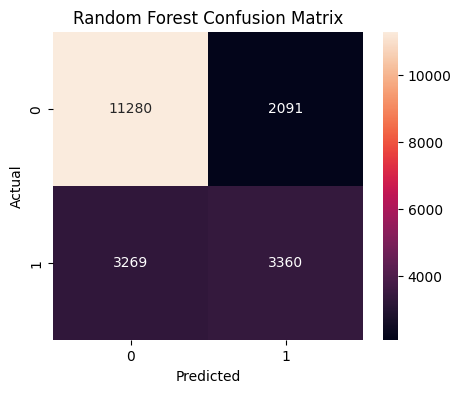

In [115]:
# Confusion Matrix - Random Forest

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()